# Function 2 - Week 5: Model Predictions

#### Model Predictions using Official Observations up to and including Week 4 return, received on **23 October 2026**.


In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "model_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review
from model_review_helpers import (
    make_regression_models, fit_model_review, review_latest_predictions,
    build_review_candidates, score_review_candidates, resolve_unmodelled_coordinates,
    query_prediction, noise_sensitivity, weight_sensitivity,
)
from model_review_plots import plot_held_out_comparison, plot_latest_predictions
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries
from plot_helpers import PLOT_CONFIG
from two_input_model_helpers import save_two_input_model_views, plot_query_proposal

In [2]:
# Settings for this run. Keep modelling assumptions and search settings here.
FUNCTION_NUMBER = 2
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
PORTAL_DECIMALS = 6

FEATURE_SETS = {"GP: x1 only": (0,)}
GP_NAMES = ["Gaussian process", *FEATURE_SETS, "GP: separate length scales"]
MODEL_SETTINGS = dict(
    noise_fraction=0.10, ridge_alpha=1.0,
    kernel_ridge_alpha=0.1, kernel_ridge_gamma=1.0,
    length_scale=0.3, length_scale_bounds=(0.03, 2.0),
    amplitude=1.0, amplitude_bounds=(0.01, 100.0),
    optimiser_restarts=3, seed=42,
)
EXPLORATION_WEIGHT = 1.96
SEARCH_SETTINGS = dict(
    broad_power=14, broad_seed=42, local_power=12, local_seed=43,
    local_radius=0.15, precision=PORTAL_DECIMALS, include_corners=True,
)
COVERAGE_SETTINGS = dict(
    max_queries=1, optimization_power=12, evaluation_power=15,
    optimization_seed=42, evaluation_seed=43, comparison_seed=42, verbose=False,
)
TIE_BREAK_SETTINGS = dict(grid_size=4097, precision=PORTAL_DECIMALS, seed=44)
PROJECTED_SOURCE_LABELS = {"GP: x1 only": "x1-only UCB with geometric x2 tie-break"}
NOISE_FRACTIONS = (0.03, MODEL_SETTINGS["noise_fraction"], 0.30)
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)

VALIDATION_MODELS = ["Ridge", "Gaussian process"]
REFERENCE_MODEL = "Kernel ridge"
VIEW_SETTINGS = dict(grid_side=61, slice_padding=0.05)
VALIDATION_SIZE = (15, 5)
LATEST_RESULT_SIZE = (11, 5.5)
PROPOSAL_MAP_SIZE = (15, 5)

In [3]:
# Validate the same snapshot used by the exploration review.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))

,observation_id,source_round,x1,x2,y,output_rank
13,round-04,4,0.17954,0.808737,0.131194,9


In [4]:
# Fit each complete estimator within every held-out fold.
models = make_regression_models(len(INPUT_COLUMNS), feature_sets=FEATURE_SETS, **MODEL_SETTINGS)
model_run = fit_model_review(models, inputs, raw_y, gp_names=GP_NAMES)
selected_model = model_run["selected_model"]
modelled_axes = FEATURE_SETS.get(model_run["selected_name"], tuple(range(len(INPUT_COLUMNS))))
display(model_run["table"].round(6))
display(pd.Series({"Selected GP": model_run["selected_name"], "Fitted kernel": model_run["fitted_kernel"]}))

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a bette

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,GP: x1 only,0.005170,0.119795,0.145783,0.675033,32.231039
1,GP: separate length scales,0.003901,0.120021,0.147264,0.676308,31.542545
2,Ridge,0.120906,0.141081,0.185709,0.794978,13.670958
3,Linear regression,0.113122,0.144931,0.187074,0.816673,13.036385
4,Kernel ridge,0.106199,0.154196,0.198864,0.868880,7.555784
5,Mean baseline,0.164789,0.177465,0.215118,1.000000,0.000000
6,Gaussian process,0.001689,0.185444,0.223697,1.044959,-3.988104


Selected GP                           GP: x1 only
Fitted kernel    1.04**2 * RBF(length_scale=0.03)
dtype: str

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Ridge,0.1714,0.0403,30.6797,0.3355,0.1924
1,Kernel ridge,0.0530,-0.0782,59.5960,1.1041,0.2052
2,Mean baseline,0.2136,0.0824,62.8455,1.0493,0.2221
3,Gaussian process,0.2136,0.0825,62.8461,0.9704,0.2310
4,GP: x1 only,0.0379,-0.0933,71.1161,2.9257,0.1491
5,Linear regression,0.0297,-0.1015,77.3710,2.1030,0.1921
6,GP: separate length scales,-0.0251,-0.1562,119.0954,8.0408,0.1466


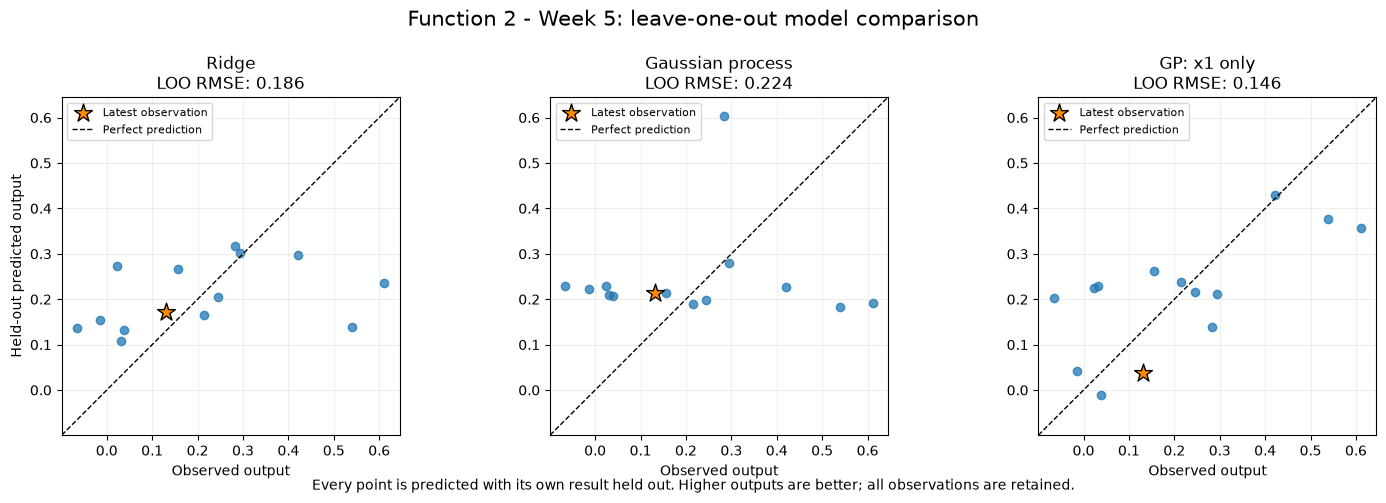

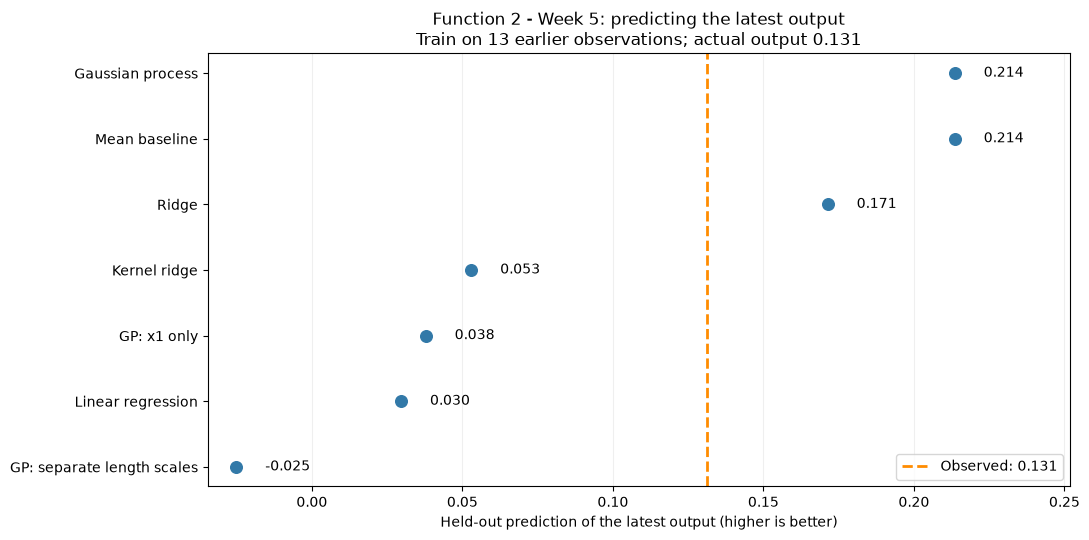

In [5]:
# This checks the latest held-out result retrospectively; it is not a saved forecast.
latest_review = review_latest_predictions(model_run["predictions"], raw_y, review["latest_mask"])
latest_output = float(raw_y[review["latest_mask"]][0])
display(latest_review.round(4))
display(plot_held_out_comparison(
    model_run["predictions"], raw_y,
    model_names=[*VALIDATION_MODELS, model_run["selected_name"]], latest_mask=review["latest_mask"],
    title=f"{TITLE}: leave-one-out model comparison", figsize=VALIDATION_SIZE,
    save_to=FIGURES_DIR / "model-comparison-validation.png",
))
display(plot_latest_predictions(
    latest_review, latest_output, n_training_rows=int((~review["latest_mask"]).sum()),
    title=f"{TITLE}: predicting the latest output", figsize=LATEST_RESULT_SIZE,
    save_to=FIGURES_DIR / "latest-output-predictions.png",
))

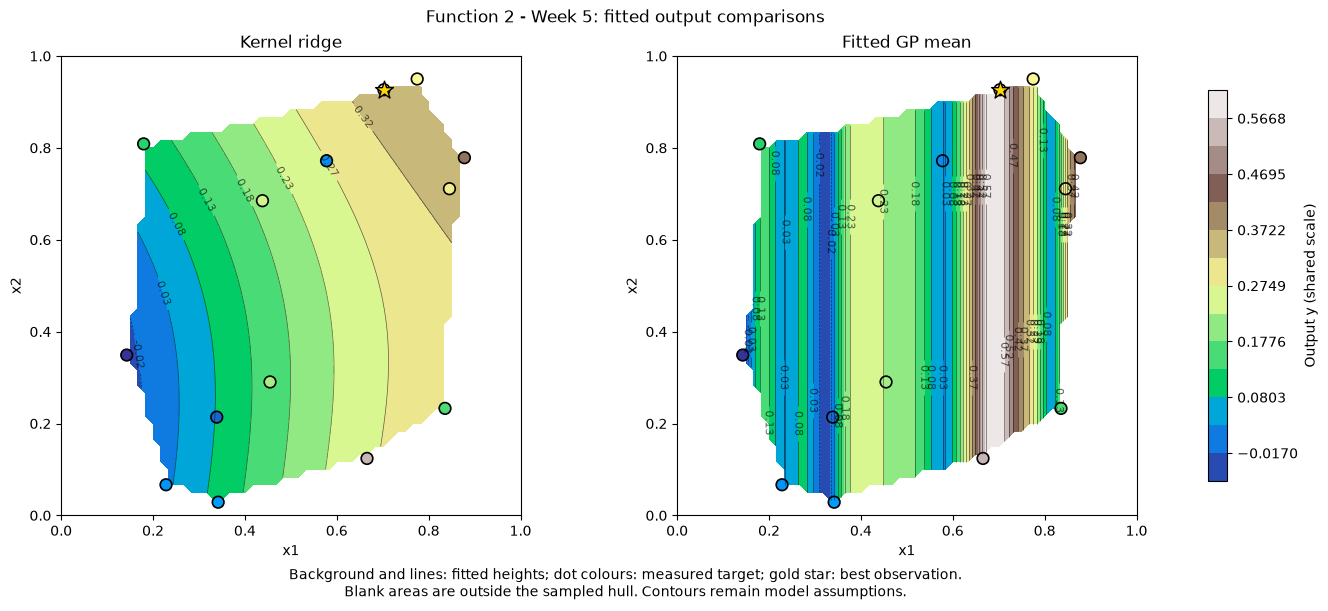

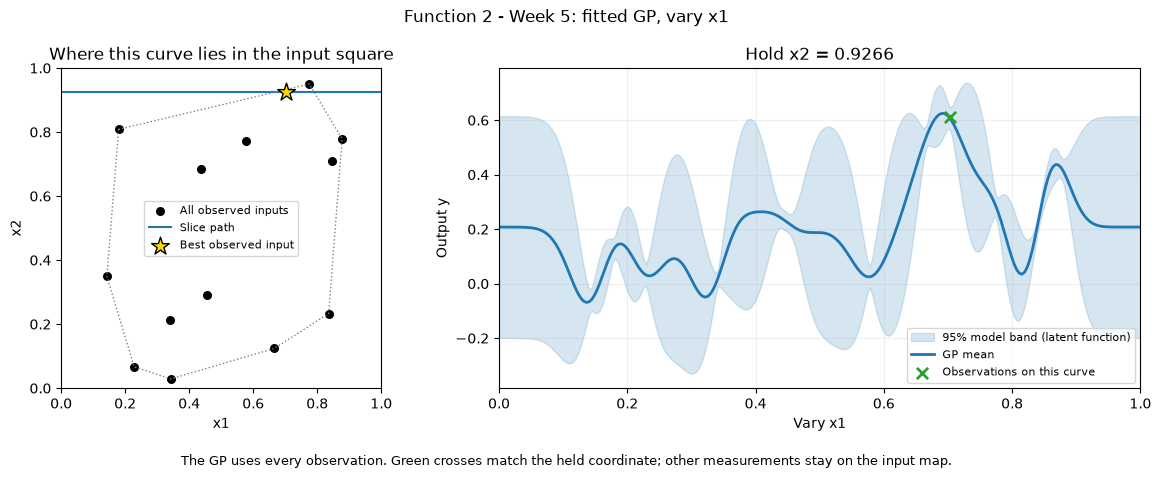

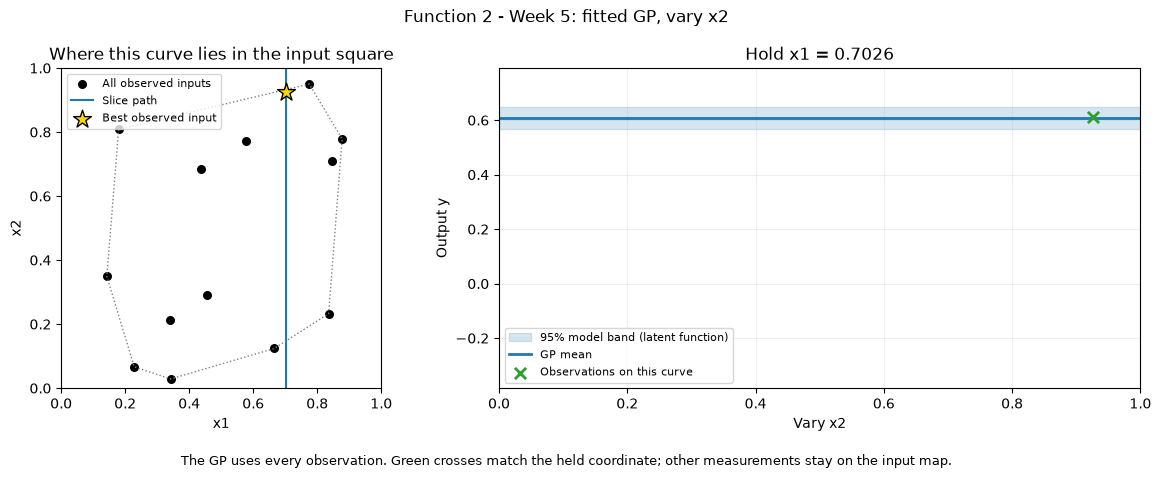

In [6]:
# Function 2 uses the two-input renderers; model calculations retain every input.
views = save_two_input_model_views(
    selected_model, model_run["fitted"][REFERENCE_MODEL], inputs, raw_y,
    title=TITLE, figures_dir=FIGURES_DIR, reference_label=REFERENCE_MODEL, **VIEW_SETTINGS,
)
display(*views["figures"])
views["terrain"].show(config=PLOT_CONFIG)

In [7]:
# Reuse the geometric coverage cache, then score the exact rounded candidate inputs.
coverage = compare_coverage_batches(
    existing=inputs, cache_dir=ANALYSIS_DIR / ".coverage-cache", **COVERAGE_SETTINGS,
)
candidates = build_review_candidates(
    inputs, anchor, coverage["proposed_batches"][1], input_columns=INPUT_COLUMNS, **SEARCH_SETTINGS,
)
scored = score_review_candidates(
    selected_model, candidates, input_columns=INPUT_COLUMNS,
    weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
by_source = scored.loc[scored.groupby("candidate_source")["ucb"].idxmax()].sort_values("ucb", ascending=False)
display(by_source.round(6))
display(pd.DataFrame(coverage["results"]))

,x1,x2,posterior_mean,posterior_sd,ucb,candidate_source
0,0.729749,0.603084,0.472454,0.135640,0.738309,Full input space
1,0.729789,0.999999,0.472237,0.135750,0.738308,Near incumbent
3122,0.997512,0.104366,0.207748,0.207495,0.614437,Single coverage query


,q,max_distance,p95_distance
0,0,0.288226,0.230260
1,1,0.288226,0.228469


In [8]:
# Resolve only coordinates omitted by the selected model; output values play no part.
recommended = scored.iloc[0]
next_query = resolve_unmodelled_coordinates(
    recommended[INPUT_COLUMNS].to_numpy(dtype=float), inputs,
    modelled_axes=modelled_axes, **TIE_BREAK_SETTINGS,
)
proposal = query_prediction(
    selected_model, next_query, inputs, raw_y,
    weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
proposal_source = PROJECTED_SOURCE_LABELS.get(model_run["selected_name"], recommended.candidate_source)
display(pd.Series(proposal))

point                         [0.729749, 0.474365]
predicted_output                          0.472454
posterior_std                              0.13564
ucb                                       0.738309
predicted_mean_improvement               -0.138751
inside_sampled_hull                           True
portal_input                     0.729749-0.474365
dtype: object

In [9]:
# Change one assumption at a time; keep the proposed point or candidate pool fixed.
noise_review = noise_sensitivity(
    selected_model, inputs, raw_y, next_query, fractions=NOISE_FRACTIONS,
    fitted_noise_fraction=MODEL_SETTINGS["noise_fraction"],
)
exploration_sensitivity = weight_sensitivity(
    scored, inputs, input_columns=INPUT_COLUMNS, modelled_axes=modelled_axes,
    weights=EXPLORATION_WEIGHTS, **TIE_BREAK_SETTINGS,
)
display(noise_review.round(6))
display(exploration_sensitivity.round(6))

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,Assumed noise fraction,Predicted output,Posterior SD
0,0.03,0.480012,0.155527
1,0.10,0.472454,0.135640
2,0.30,0.515039,0.068032


,Weight,x1,x2,Predicted output,Posterior SD
0,0.00,0.691738,0.475097,0.625282,0.046854
1,1.00,0.687791,0.475097,0.623018,0.053736
2,1.96,0.729749,0.474365,0.472454,0.135640
3,3.00,0.733777,0.474121,0.451320,0.144633


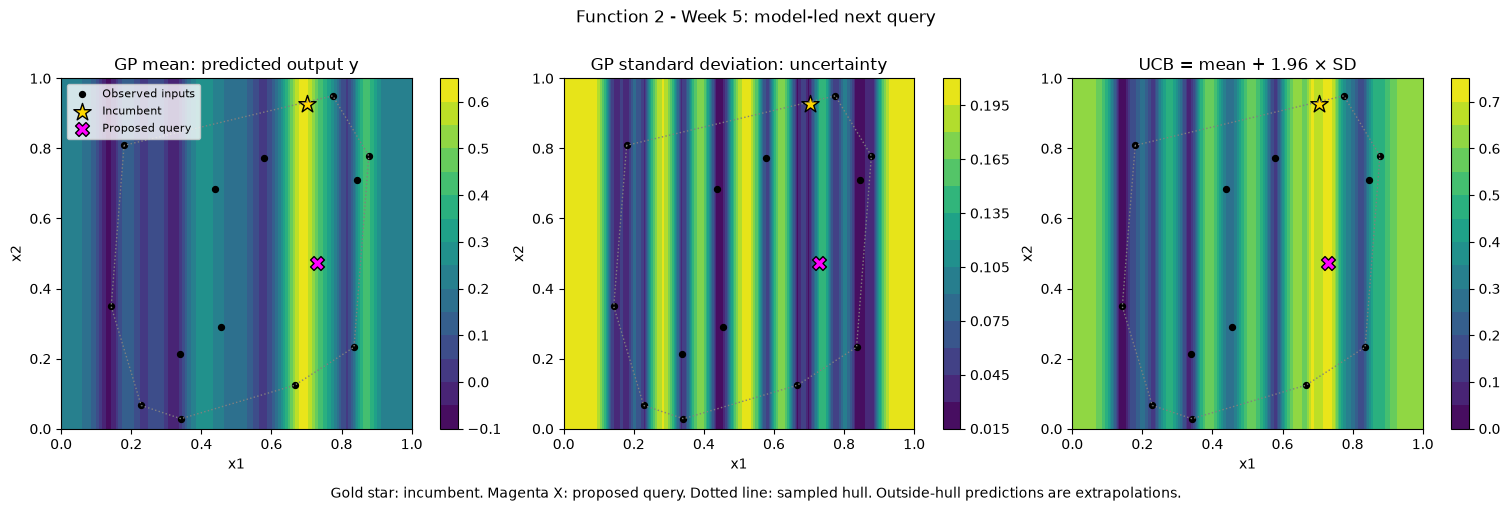

In [10]:
# Keep predicted output, model uncertainty and the selection score on separate maps.
plot_query_proposal(
    views["grid"], inputs, anchor, next_query, title=f"{TITLE}: model-led next query",
    weight=EXPLORATION_WEIGHT, figsize=PROPOSAL_MAP_SIZE,
    save_to=FIGURES_DIR / "model-query-proposal.png",
)

In [11]:
# Preserve the saved summary contract read by the separate cohort comparison.
analysis_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(raw_y),
    "query_model": model_run["selected_name"], "proposal_status": "proposed_not_submitted",
    "portal_input": proposal["portal_input"], "point": proposal["point"],
    "predicted_output": proposal["predicted_output"], "posterior_std": proposal["posterior_std"],
    "ucb_weight": EXPLORATION_WEIGHT, "candidate_source": proposal_source,
    "candidate_count": len(scored),
    "x2_tie_break_candidates": TIE_BREAK_SETTINGS["grid_size"] if len(modelled_axes) < len(INPUT_COLUMNS) else 0,
    "inside_sampled_hull": proposal["inside_sampled_hull"], "best_observed_output": float(raw_y.max()),
    "gp_rmse": model_run["selected_rmse"], "baseline_rmse": model_run["baseline_rmse"],
    "gp_baseline_rmse_ratio": model_run["selected_rmse"] / model_run["baseline_rmse"],
    "lowest_rmse_model": model_run["table"].iloc[0]["Model"],
    "distinct_weight_choices": len(exploration_sensitivity[INPUT_COLUMNS].drop_duplicates()),
    "remaining_queries": remaining_queries(WEEK_DIR),
}
print(json.dumps(analysis_summary, indent=2))

{
  "function": 2,
  "week": 5,
  "observations": 14,
  "query_model": "GP: x1 only",
  "proposal_status": "proposed_not_submitted",
  "portal_input": "0.729749-0.474365",
  "point": [
    0.729749,
    0.474365
  ],
  "predicted_output": 0.4724544855982812,
  "posterior_std": 0.13563989964509018,
  "ucb_weight": 1.96,
  "candidate_source": "x1-only UCB with geometric x2 tie-break",
  "candidate_count": 20489,
  "x2_tie_break_candidates": 4097,
  "inside_sampled_hull": true,
  "best_observed_output": 0.6112052157614438,
  "gp_rmse": 0.14578291498430085,
  "baseline_rmse": 0.21511752990375593,
  "gp_baseline_rmse_ratio": 0.6776896101843697,
  "lowest_rmse_model": "GP: x1 only",
  "distinct_weight_choices": 4,
  "remaining_queries": 9
}
